# Butterworth Coefficient Table

In this section, we are going to do the following activities:

- generate the normalized Butterworth coefficients by using SymPy
- obtain the continuous-time low-pass and high-pass transfer functions
- apply the bilinear transform to obtain the digital filter coefficients
- check our digital coefficients against SciPy

This table extends the second-order Butterworth examples in the **Digital Low-Pass Filter** and **Digital High-Pass Filter** chapters.

This chapter provides the continuous-time Butterworth prototype used in the {doc}`Digital Low-Pass Filter <digital-filter>` and {doc}`Digital High-Pass Filter <digital-filter-2>` chapters. The normalized prototype has a cutoff of $1\;\mathrm{rad/s}$; we scale it to $\omega_c$ before applying the bilinear transformation.

## Required Imports

In [9]:
from sympy import *
from IPython.display import display, Markdown
from mathprint import mprint
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

s, p, q = symbols('s p q')
wc, Ts = symbols('omega_c T_s', positive=True)

## Normalized Butterworth Polynomial

The Butterworth filter has a maximally flat magnitude response in the passband. For a normalized **analog low-pass** filter, the cutoff angular frequency is $1\;\mathrm{rad/s}$.

We write its denominator as

$$
B_n(p)=p^n+a_1p^{n-1}+\cdots+a_n, \qquad p=\frac{s}{\omega_c}.
$$

For the stable Butterworth prototype, the polynomial can be constructed from first- and second-order factors:

$$
B_n(p)=(p+1)^{n\bmod 2}
\prod_{k=1}^{\lfloor n/2\rfloor}
\left[p^2+2\sin\left(\frac{(2k-1)\pi}{2n}\right)p+1\right].
$$

The factors select only the **left-half-plane poles**. We can generate the polynomial with SymPy rather than looking up its coefficients in a printed table.

In [10]:
def butterworth_polynomial(n, variable=p):
    if not isinstance(n, int) or n < 1:
        raise ValueError('Filter order must be a positive integer.')

    B = variable + 1 if n % 2 else S.One
    for k in range(1, n // 2 + 1):
        angle = pi * (2*k - 1) / (2*n)
        B *= variable**2 + 2*sin(angle)*variable + 1

    return expand(B)

for n in range(1, 5):
    mprint(r'B_{', str(n), '}(p)=', latex(butterworth_polynomial(n)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Butterworth Coefficient Table

The coefficients below are ordered from the highest power to the constant term:

$$B_n(p)=a_0p^n+a_1p^{n-1}+\cdots+a_n,\qquad a_0=a_n=1.$$

We can generate the table for any order. Here, we use $n=1,\ldots,8$ and display the coefficients to five decimal places.

In [11]:
table_rows = [r"| Order $n$ | Coefficients $[a_0,a_1,\ldots,a_n]$ |",
              "|:---:|:---|"]

for n in range(1, 9):
    B = Poly(butterworth_polynomial(n), p)
    coefficients = [float(value.evalf()) for value in B.all_coeffs()]
    table_rows.append(
        f"| {n} | " + ", ".join(f"{value:.5f}" for value in coefficients) + " |"
    )

display(Markdown("\n".join(table_rows)))

| Order $n$ | Coefficients $[a_0,a_1,\ldots,a_n]$ |
|:---:|:---|
| 1 | 1.00000, 1.00000 |
| 2 | 1.00000, 1.41421, 1.00000 |
| 3 | 1.00000, 2.00000, 2.00000, 1.00000 |
| 4 | 1.00000, 2.61313, 3.41421, 2.61313, 1.00000 |
| 5 | 1.00000, 3.23607, 5.23607, 5.23607, 3.23607, 1.00000 |
| 6 | 1.00000, 3.86370, 7.46410, 9.14162, 7.46410, 3.86370, 1.00000 |
| 7 | 1.00000, 4.49396, 10.09783, 14.59179, 14.59179, 10.09783, 4.49396, 1.00000 |
| 8 | 1.00000, 5.12583, 13.13707, 21.84615, 25.68836, 21.84615, 13.13707, 5.12583, 1.00000 |

### From the table to a transfer function

To use the normalized polynomial at an arbitrary cutoff frequency $\omega_c$, replace $p$ with $s/\omega_c$:

$$
\begin{aligned}
D_n(s)&=\omega_c^n B_n(s/\omega_c),\\
H_{LP}(s)&=\frac{\omega_c^n}{D_n(s)},\\
H_{HP}(s)&=\frac{s^n}{D_n(s)}.
\end{aligned}
$$

**Note:** $\omega_c$ is an *angular* frequency in $\mathrm{rad/s}$, not Hz. For a continuous-time cutoff frequency $f_c$ in Hz, $\omega_c=2\pi f_c$.

In [12]:
def butterworth_analog(n, cutoff=wc, kind='lowpass'):
    if kind not in ('lowpass', 'highpass'):
        raise ValueError("kind must be 'lowpass' or 'highpass'")

    D = expand(cutoff**n * butterworth_polynomial(n, s/cutoff))
    N = cutoff**n if kind == 'lowpass' else s**n
    return factor(N/D)

H_LP = butterworth_analog(2, wc, 'lowpass')
H_HP = butterworth_analog(2, wc, 'highpass')
mprint(r'H_{\mathrm{LP}}(s)=', latex(H_LP))
mprint(r'H_{\mathrm{HP}}(s)=', latex(H_HP))

assert simplify(H_LP - wc**2/(s**2+sqrt(2)*wc*s+wc**2)) == 0
assert simplify(H_HP - s**2/(s**2+sqrt(2)*wc*s+wc**2)) == 0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

These are precisely the **second-order low-pass and standard high-pass Butterworth** transfer functions used in our two digital-filter chapters.

Notice that $1-H_{LP}(s)$ is **not** the standard second-order Butterworth high-pass filter: its numerator is $s^2+\sqrt{2}\omega_cs$, rather than $s^2$. This is why the complementary high-pass example in the other notebook has a different low-frequency slope.

## Discretization with Bilinear Transformation

As in the existing notebooks, we use the Tustin substitution:

$$
s=\frac{2}{T_s}\frac{1-z^{-1}}{1+z^{-1}}.
$$

Let $q=z^{-1}$ and define the dimensionless quantity

$$r=\frac{\omega_cT_s}{2}.$$

For a second-order Butterworth filter, multiplying both numerator and denominator by $(1+q)^2$ gives

$$
\begin{aligned}
D(q)&=(1-q)^2+\sqrt{2}r(1-q)(1+q)+r^2(1+q)^2,\\
N_{LP}(q)&=r^2(1+q)^2,\\
N_{HP}(q)&=(1-q)^2.
\end{aligned}
$$

Thus both filters share the same denominator coefficients.

In [13]:
r = symbols('r', positive=True)
D = expand((1-q)**2 + sqrt(2)*r*(1-q)*(1+q) + r**2*(1+q)**2)
N_LP = expand(r**2*(1+q)**2)
N_HP = expand((1-q)**2)

a0 = Poly(D, q).nth(0)
a = [factor(Poly(D, q).nth(i)/a0) for i in range(3)]
b_lp = [factor(Poly(N_LP, q).nth(i)/a0) for i in range(3)]
b_hp = [factor(Poly(N_HP, q).nth(i)/a0) for i in range(3)]

# One complete subscript: b_{LP,0}, not b_{LP}_{0}.
for name, values in [('a', a), ('LP', b_lp), ('HP', b_hp)]:
    for i, value in enumerate(values):
        if name == 'a':
            lhs = rf'a_{{{i}}}'
        else:
            lhs = rf'b_{{\mathrm{{{name}}},{i}}}'
        mprint(lhs, ' = ', latex(value))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### The Difference Equation

With the digital transfer function written as

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}},$$

we get

$$
\boxed{y[k]=b_0x[k]+b_1x[k-1]+b_2x[k-2]-a_1y[k-1]-a_2y[k-2].}
$$

This is the same second-order difference equation already implemented in the low-pass and high-pass notebooks. Only the numerator coefficients change between the two filters.

## Numerical Example

Let the sampling frequency be $f_s=100\;\mathrm{Hz}$, and the required digital cutoff frequency be $f_c=10\;\mathrm{Hz}$.

The bilinear transform warps the frequency axis. If the digital filter must have its $-3\;\mathrm{dB}$ cutoff at exactly $f_c$, we use the **prewarped** analog cutoff frequency:

$$
\omega_{c,\mathrm{prewarp}}=2f_s\tan\left(\pi\frac{f_c}{f_s}\right),
\qquad r=\tan\left(\pi\frac{f_c}{f_s}\right).
$$

The original notebooks use the bilinear substitution without prewarping. That is also valid, but then the digital cutoff frequency is shifted slightly.

In [14]:
fs, fc = 100.0, 10.0
r_value = np.tan(np.pi * fc / fs)

coef = lambda exprs: np.array([float(v.subs(r, r_value)) for v in exprs])
a_num = coef(a)
b_lp_num = coef(b_lp)
b_hp_num = coef(b_hp)

print('Denominator a:', np.round(a_num, 8))
print('Low-pass b:  ', np.round(b_lp_num, 8))
print('High-pass b: ', np.round(b_hp_num, 8))

for kind, b in [('lowpass', b_lp_num), ('highpass', b_hp_num)]:
    expected_b, expected_a = signal.butter(2, fc, btype=kind, fs=fs)
    np.testing.assert_allclose(b, expected_b, atol=1e-12)
    np.testing.assert_allclose(a_num, expected_a, atol=1e-12)
    print(kind, ': coefficients match scipy.signal.butter()')

Denominator a: [ 1.        -1.1429805  0.4128016]
Low-pass b:   [0.06745527 0.13491055 0.06745527]
High-pass b:  [ 0.63894553 -1.27789105  0.63894553]
lowpass : coefficients match scipy.signal.butter()
highpass : coefficients match scipy.signal.butter()


### Frequency Response

We can also check the cutoff frequency directly. The second-order low-pass filter and the standard second-order high-pass filter must both have magnitude $1/\sqrt{2}$ (approximately $-3.01\;\mathrm{dB}$) at the cutoff.

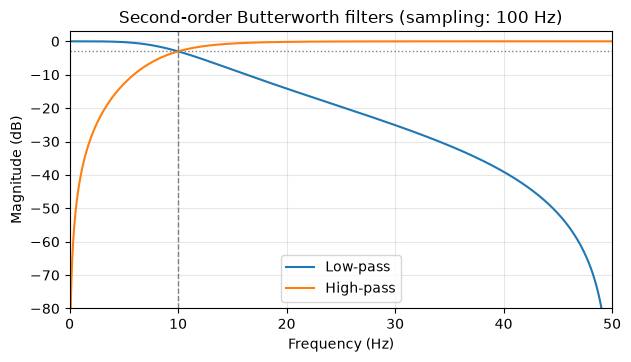

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for label, b in [('Low-pass', b_lp_num), ('High-pass', b_hp_num)]:
    freq, h = signal.freqz(b, a_num, worN=2048, fs=fs)
    ax.plot(freq, 20*np.log10(np.maximum(abs(h), 1e-12)), label=label)
    idx = np.argmin(abs(freq-fc))
    assert abs(20*np.log10(abs(h[idx])) + 3.0103) < 0.06

ax.axvline(fc, linestyle='--', linewidth=1, color='gray')
ax.axhline(-3.0103, linestyle=':', linewidth=1, color='gray')
ax.set(xlabel='Frequency (Hz)', ylabel='Magnitude (dB)',
       title='Second-order Butterworth filters (sampling: 100 Hz)')
ax.set_xlim(0, fs/2)
ax.set_ylim(-80, 3)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Higher-Order Digital Butterworth Filters

The coefficient table gives us the analog prototypes for any order. To obtain a digital filter of order $n$, we use the same bilinear transform and normalize the resulting coefficients.

For higher orders, directly implementing one large difference equation can introduce numerical errors. In practice, digital filters of higher order are often implemented as cascaded **second-order sections (SOS)**.

In [16]:
sos = signal.butter(6, fc, btype='lowpass', fs=fs, output='sos')
print('Sixth-order low-pass Butterworth: cascaded second-order sections')
print('Each row: [b0, b1, b2, a0, a1, a2]')
print(np.round(sos, 7))

Sixth-order low-pass Butterworth: cascaded second-order sections
Each row: [b0, b1, b2, a0, a1, a2]
[[ 3.4050000e-04  6.8110000e-04  3.4050000e-04  1.0000000e+00
  -1.0320694e+00  2.7570790e-01]
 [ 1.0000000e+00  2.0000000e+00  1.0000000e+00  1.0000000e+00
  -1.1429805e+00  4.1280160e-01]
 [ 1.0000000e+00  2.0000000e+00  1.0000000e+00  1.0000000e+00
  -1.4043849e+00  7.3591520e-01]]


## Summary

- **Butterworth coefficient table:** fixed for each normalized analog order $n$.
- **Analog low-pass and high-pass:** obtained from the same polynomial $B_n$ by changing the numerator and scaling with $\omega_c$.
- **Digital filter coefficients:** depend on the order, cutoff frequency, and sampling period.
- **Prewarping:** allows the digital cutoff to match the requested frequency after the bilinear transform.
- **Higher-order implementations:** prefer SOS for numerical robustness.
